## Context

This notebook accompanies User Guide section 23 (Release gates and SPC). It builds a `TieredReleaseGate`, runs `check_all_tiers` over three simulated `RunMetrics`, then layers an `SPCSlopeCoAttestor` on top: calibrated against a healthy baseline and exercised against an injected-drift trend so the slope alert fires without flicker on the healthy series.

In [ ]:
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _shared as ug
ug.bootstrap_runtime()  # stubs modeva if absent
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


### Concept: structural gate plus trend co-attestor

A point-threshold gate decides on a single run. It answers: does *this* run clear the bar for tier $T$? It is binary by design — pass or block — because that is what an audit trail can record without ambiguity.

But a release that always passes the gate can still be degrading. If accuracy drops $1\%$ per release across ten releases, every individual run may pass the `action_taking` floor of $0.85$ until the eleventh release falls off the cliff. The gate is structurally blind to the trend. SPC (statistical process control) answers the second question: is the *sequence* moving in the wrong direction?

Conflating the two destroys the audit signal. A slope-only block flickers on noisy series; a slope-as-advisory hides the SPC firing in the audit log. `SPCSlopeCoAttestor` follows the Ch 13 `HolonomyCoAttestor` pattern: a **three-state verdict** $\{\textsf{pass}, \textsf{flag}, \textsf{block}\}$ with the lattice $\textsf{block} \supset \textsf{flag} \supset \textsf{pass}$. Structural fail blocks. Structural pass with slope alert flags. Structural pass with no alert passes.

We will (1) check three runs against the three tiers, (2) build a healthy baseline `RunTrend` and calibrate slope thresholds from it, (3) inject a drift trajectory and confirm the co-attestor fires on it but stays silent on the healthy continuation.

In [ ]:
from knowlytix.harness.governance.release_gates import (
    TieredReleaseGate, RunMetrics, RunTrend,
)
from knowlytix.harness.governance.release_gate_co_attestor import (
    SPCSlopeCoAttestor, SPCSlopeConfig,
)

gate = TieredReleaseGate()
for tier_name, t in gate.TIERS_RUNTIME.items():
    print(f'  {tier_name:14s}  '
          f'min_acc={t.min_accuracy:.2f}  '
          f'min_conf={t.min_confidence:.2f}  '
          f'max_rob={t.max_robustness_drop:.2f}  '
          f'min_air={t.min_fairness_air:.2f}')


In [3]:
# (1) Three simulated RunMetrics: well-clear, marginal,
# and below-bar.
runs = [
    RunMetrics(accuracy=0.92, confidence=0.78,
               robustness_drop=0.03, fairness_air=0.95,
               tool_calls=15, policy_blocks=0,
               run_id='run_clear'),
    RunMetrics(accuracy=0.83, confidence=0.55,
               robustness_drop=0.08, fairness_air=0.90,
               tool_calls=18, policy_blocks=1,
               run_id='run_marginal'),
    RunMetrics(accuracy=0.72, confidence=0.40,
               robustness_drop=0.15, fairness_air=0.65,
               tool_calls=12, policy_blocks=3,
               run_id='run_low'),
]
for m in runs:
    print(f'\n--- {m.run_id} ---')
    results = gate.check_all_tiers(m)
    for tier, r in results.items():
        status = 'PASS' if r.passed else 'FAIL'
        print(f'  {tier:14s}: {status}')
        if not r.passed:
            print(f'    blocking: '
                  f'{"; ".join(r.blocking_reasons)}')



--- run_clear ---
  advisory      : PASS
  recommendation: PASS
  action_taking : PASS

--- run_marginal ---
  advisory      : PASS
  recommendation: PASS
  action_taking : FAIL
    blocking: accuracy 0.8300 < 0.85; confidence 0.5500 < 0.70; robustness_drop 0.0800 > 0.05

--- run_low ---
  advisory      : PASS
  recommendation: FAIL
    blocking: accuracy 0.7200 < 0.80; confidence 0.4000 < 0.50; robustness_drop 0.1500 > 0.10
  action_taking : FAIL
    blocking: accuracy 0.7200 < 0.85; confidence 0.4000 < 0.70; robustness_drop 0.1500 > 0.05; fairness_air 0.6500 < 0.80


In [4]:
# (2) Healthy baseline trend: small natural variation, no
# systematic drift.  We use this to calibrate per-metric
# slope thresholds.
import numpy as np
rng = np.random.default_rng(seed=42)

def baseline_run(i, rng):
    return RunMetrics(
        accuracy=0.90 + rng.normal(0, 0.005),
        confidence=0.72 + rng.normal(0, 0.005),
        robustness_drop=0.04 + rng.normal(0, 0.003),
        fairness_air=0.92 + rng.normal(0, 0.005),
        tool_calls=15, policy_blocks=0,
        run_id=f'baseline_{i:02d}',
    )

baseline = [baseline_run(i, rng) for i in range(20)]
baseline_trend = RunTrend(metrics=list(baseline))

attestor = SPCSlopeCoAttestor(
    gate=gate,
    config=SPCSlopeConfig(min_runs_for_alert=5),
)
fitted = attestor.calibrate_from_canonical(
    baseline, target_quantile=0.05)
attestor.config = fitted
print('Calibrated thresholds (healthy 5th percentile):')
print(f'  min_acc_slope  = {fitted.min_acc_slope:+.5f}')
print(f'  min_conf_slope = {fitted.min_conf_slope:+.5f}')
print(f'  min_fair_slope = {fitted.min_fair_slope:+.5f}')
print(f'  max_rob_slope  = {fitted.max_rob_slope:+.5f}')


Calibrated thresholds (healthy 5th percentile):
  min_acc_slope  = -0.00192
  min_conf_slope = -0.00053
  min_fair_slope = -0.00122
  max_rob_slope  = +0.00072


In [5]:
# (3) Inject drift: 10 runs whose accuracy and confidence
# drift downward by ~0.01 per run.  Each individual run
# still clears the action_taking floor for the first few,
# but the slope alert must fire as soon as we have enough
# points.
rng2 = np.random.default_rng(seed=7)
drift = []
for i in range(10):
    drift.append(RunMetrics(
        accuracy=0.92 - 0.012 * i + rng2.normal(0, 0.004),
        confidence=0.75 - 0.010 * i + rng2.normal(0, 0.004),
        robustness_drop=0.04 + 0.008 * i
                       + rng2.normal(0, 0.002),
        fairness_air=0.92 + rng2.normal(0, 0.004),
        tool_calls=15, policy_blocks=0,
        run_id=f'drift_{i:02d}',
    ))
drift_trend = RunTrend(metrics=list(drift))

# Healthy continuation for the negative control:
rng3 = np.random.default_rng(seed=99)
healthy = [baseline_run(i, rng3) for i in range(10)]
healthy_trend = RunTrend(metrics=list(healthy))

# Evaluate the latest run against action_taking with
# the trend supplied as the SPC window.
drift_verdict = attestor.evaluate(
    drift[-1], 'action_taking', trend=drift_trend)
healthy_verdict = attestor.evaluate(
    healthy[-1], 'action_taking', trend=healthy_trend)

print(f'drift verdict: {drift_verdict.verdict}'
      f' (structural_passed={drift_verdict.structural_passed},'
      f' slope_alerted={drift_verdict.slope_alerted})')
for r in drift_verdict.flag_reasons:
    print(f'  flag: {r}')
for r in drift_verdict.blocking_reasons:
    print(f'  block: {r}')

print(f'healthy verdict: {healthy_verdict.verdict}'
      f' (structural_passed={healthy_verdict.structural_passed},'
      f' slope_alerted={healthy_verdict.slope_alerted})')


drift verdict: block (structural_passed=False, slope_alerted=True)
  flag: accuracy slope -0.01205 below -0.00192
  flag: confidence slope -0.00969 below -0.00053
  flag: robustness_drop slope +0.00785 above +0.00072
  block: accuracy 0.8119 < 0.85
  block: confidence 0.6635 < 0.70
  block: robustness_drop 0.1108 > 0.05
healthy verdict: pass (structural_passed=True, slope_alerted=False)


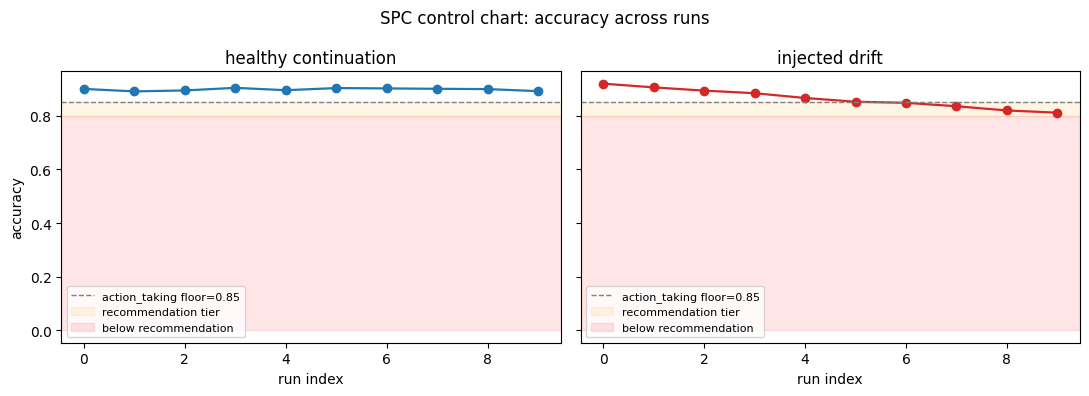

In [6]:
# Visualization: SPC control chart with alert zones.
# Healthy baseline (blue) vs drift trajectory (red),
# overlaid with the action_taking accuracy floor.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4),
                         sharey=True)
floor = (gate.TIERS_RUNTIME['action_taking']
         .min_accuracy)

for ax, runs_, color, title in [
    (axes[0], healthy, 'tab:blue',
     'healthy continuation'),
    (axes[1], drift, 'tab:red',
     'injected drift'),
]:
    xs = list(range(len(runs_)))
    ys = [r.accuracy for r in runs_]
    ax.plot(xs, ys, marker='o', color=color, lw=1.6)
    ax.axhline(floor, color='gray', linestyle='--',
               linewidth=1, label=f'action_taking floor='
                                 f'{floor:.2f}')
    ax.axhspan(0.80, floor, alpha=0.10,
               color='orange',
               label='recommendation tier')
    ax.axhspan(0.0, 0.80, alpha=0.10,
               color='red', label='below recommendation')
    ax.set_xlabel('run index')
    ax.set_title(title)
    ax.legend(loc='lower left', fontsize=8)
axes[0].set_ylabel('accuracy')
fig.suptitle('SPC control chart: accuracy across runs')
fig.tight_layout()
plt.show()


### Exercises

1. Construct a `RunMetrics` whose accuracy is `float('nan')` and confirm that `gate.check(m, 'advisory')` returns `passed=False` with a non-finite blocking reason. NaN/Inf must fail closed regardless of the comparison direction.
2. Try to build a `TieredReleaseGate` with a custom `recommendation` tier whose `min_accuracy=0.65` (below `advisory`'s $0.70$). Confirm that `__init__` raises `ValueError` because the threshold set violates monotonicity.
3. Reduce the drift slope from $-0.012$ per run to $-0.002$ per run and confirm the co-attestor's calibrated threshold no longer fires. The 5th-percentile calibration is exactly the noise-tolerance dial: too tight and natural variation flickers, too loose and real degradation slips through.

### What you should now be able to do

- Build a `TieredReleaseGate`, run `check_all_tiers` over a `RunMetrics`, and read the per-tier `blocking_reasons` from the returned `GateResult`.
- Recognize the `RunMetrics` schema (accuracy, confidence, robustness_drop, fairness_air, tool_calls, policy_blocks) and the directional convention each metric obeys.
- Build an `SPCSlopeCoAttestor`, calibrate its slope thresholds from a healthy `RunTrend` via `calibrate_from_canonical`, and evaluate the three-state verdict on a current run.
- Distinguish a `block` (structural fail) from a `flag` (structural pass with slope alert) and explain why those are not the same audit signal.

### Cross-references

- USER_GUIDE.md §23 (Release gates and SPC)
- `governed_agent/release_gates.py:TieredReleaseGate`, `RunMetrics`, `RunTrend`
- `governed_agent/release_gate_co_attestor.py:SPCSlopeCoAttestor`, `SPCSlopeConfig`
- `gms_agent_builder_ext/chapters/ch15.tex` for the 200-probe adversarial cohort and the 14641-point monotonicity sweep

In [7]:
# Final assertion: drift flagged, healthy passes.
assert drift_verdict.verdict in {'flag', 'block'}, \
    f'drift run must not pass; got '\
    f'{drift_verdict.verdict}'
assert drift_verdict.slope_alerted, \
    'SPC slope alert must fire on drift trajectory'
assert healthy_verdict.verdict == 'pass', \
    f'healthy continuation must pass; got '\
    f'{healthy_verdict.verdict}'
assert not healthy_verdict.slope_alerted, \
    'SPC must not flicker on healthy variation'
print(f'OK: drift -> {drift_verdict.verdict}; '
      f'healthy -> {healthy_verdict.verdict}')


OK: drift -> block; healthy -> pass
